N=20

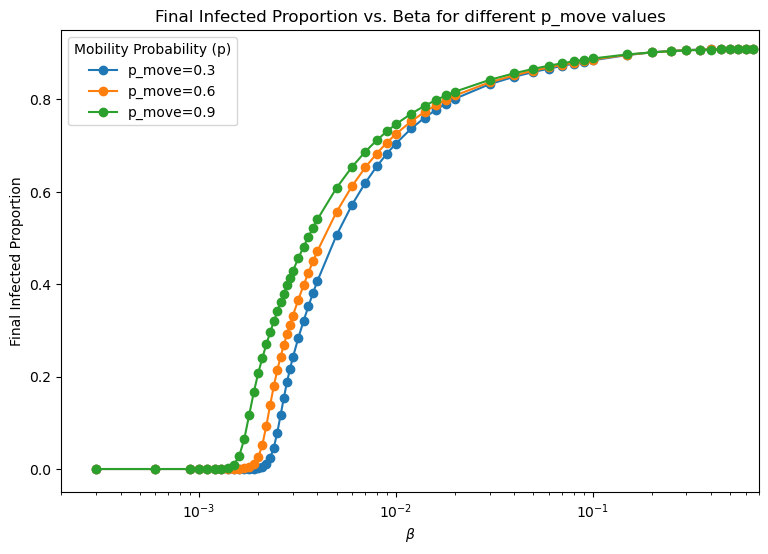

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import random
import pandas as pd

# 设置随机种子以确保结果可复现
np.random.seed(42)
random.seed(42)

# 生成BA无标度网络并为每条边分配1到10之间的随机权重，返回邻接矩阵W
def generate_ba_scale_free_network(N, m):
    G = nx.barabasi_albert_graph(N, m)
    for u, v in G.edges():
        G[u][v]['weight'] = random.randint(1, 10)
    W = nx.to_numpy_array(G, weight='weight')
    return W

# 计算C矩阵
def calculate_C_matrix(W):
    N = W.shape[0]
    C = np.zeros_like(W, dtype=float)
    for i in range(N):
        row_sum = np.sum(W[i, :])
        if row_sum > 0:
            C[i, :] = W[i, :] / row_sum
    return C

# 生成每个子种群的网络并计算平均度
def generate_subpopulations(N):
    n = np.full(N, 100)
    average_degrees = n * 0.1
    return n, average_degrees

# 运行模拟实验
def run_simulation(beta, N, initial_infected_density, n, average_degrees, C, mu, p_move, alpha, steps):
    rho = np.full(N, initial_infected_density)
    for t in range(steps):
        new_rho = np.zeros(N)
        R_i = np.zeros(N)
        D_i = np.zeros(N)
        P_i = np.zeros(N)
        Pi_i = np.zeros(N)
        for i in range(N):
            R_i[i] = 1 - (1 - beta) ** ((1 - p_move) * average_degrees[i] * rho[i] +
                                     np.sum([p_move * C[j, i] * average_degrees[j] * rho[j] for j in range(N)]))
            D_i[i] = 1 - (1 - beta) ** ((1 - p_move) * n[i] * rho[i] * 0.9  +
                                     np.sum([p_move * C[j, i] * n[j] * rho[j] for j in range(N)]))
            P_i[i] = alpha * R_i[i] + (1 - alpha) * D_i[i]
        for i in range(N):
            Pi_i[i] = (1 - p_move) * P_i[i] + p_move * np.sum([C[i, j] * P_i[j] for j in range(N)])
            new_rho[i] = (1 - mu) * rho[i] + (1 - rho[i]) * Pi_i[i]
        rho = new_rho
    return np.mean(rho)

# 初始变量
N = 20
m = 5
initial_infected_density = 0.01

mu = 0.1
alpha = 0.6
steps = 200

# 方法一：生成BA无标度网络
W = generate_ba_scale_free_network(N, m)

# 方法二：计算C矩阵
C = calculate_C_matrix(W)

# 方法三：生成每个子种群的网络并计算平均度
n, average_degrees = generate_subpopulations(N)

# 方法四：生成不同区间的 beta 值
beta_values = np.concatenate([
    np.arange(0.0003, 0.001, 0.0003),
    np.arange(0.001, 0.003, 0.0001),
    np.arange(0.003, 0.004, 0.0002),
    np.arange(0.004, 0.01, 0.001),
    np.arange(0.01, 0.02, 0.002),
    np.arange(0.02, 0.1, 0.01),
    np.arange(0.1, 0.7, 0.05)
])

# 不同的移动概率值
p_move_values = [ 0.3, 0.6,0.9]

# 记录不同p_move值下的结果
all_results = {}

for p_move in p_move_values:

    # results存储最终不同beta值对应final infected proportion
    results = []

    for beta in beta_values:
        simulation_results = []
        for _ in range(30):  # 平均运行n次
            result = run_simulation(beta, N, initial_infected_density, n, average_degrees, C, mu, p_move, alpha, steps)
            simulation_results.append(result)
        average_result = np.mean(simulation_results)
        results.append(average_result)

    all_results[p_move] = results

    # 转换results为DataFrame并保存到CSV文件
    df = pd.DataFrame({
        'beta': beta_values,
        'final_infected_proportion': results
    })
    df.to_csv(f'../data/BA_MMCA_p_{p_move}.csv', index=False)

# 绘制结果
plt.figure(figsize=(9, 6))
for p_move, results in all_results.items():
    plt.plot(beta_values, results, marker='o', label=f'p_move={p_move}')
# plt.plot(beta_values, all_results[0.9], label=f'p_move=0.9')
plt.xlabel(r'$\beta$')
plt.ylabel('Final Infected Proportion')
plt.xscale("log")
plt.yscale("linear")
plt.ylim(-0.05, 0.95)  # 设置y轴范围
plt.yticks(np.arange(0.0, 0.95, 0.2))
plt.xticks([0.001, 0.01, 0.1], [ "$10^{-3}$", "$10^{-2}$", "$10^{-1}$"])
plt.xlim(0.0002, 0.7)  # 设置x轴范围
plt.title('Final Infected Proportion vs. Beta for different p_move values')
plt.legend(title='Mobility Probability (p)')
plt.show()


N=50

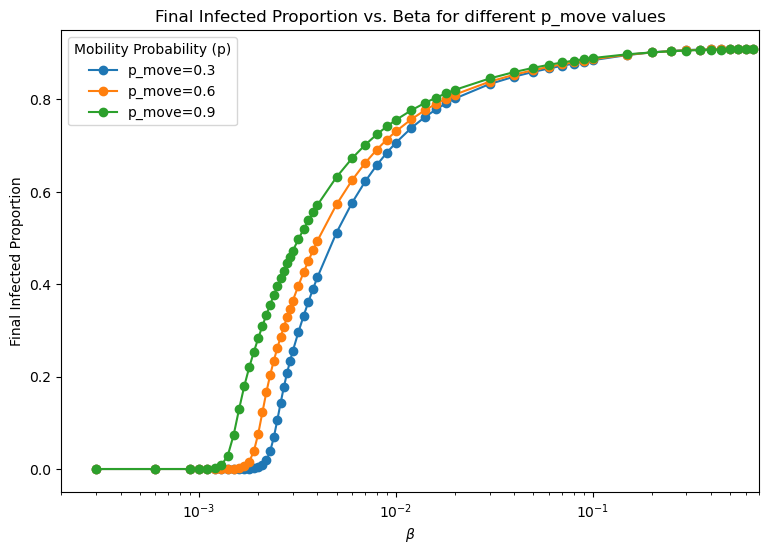

In [3]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import random
import pandas as pd

# 设置随机种子以确保结果可复现
np.random.seed(42)
random.seed(42)

# 生成BA无标度网络并为每条边分配1到10之间的随机权重，返回邻接矩阵W
def generate_ba_scale_free_network(N, m):
    G = nx.barabasi_albert_graph(N, m)
    for u, v in G.edges():
        G[u][v]['weight'] = random.randint(1, 10)
    W = nx.to_numpy_array(G, weight='weight')
    return W

# 计算C矩阵
def calculate_C_matrix(W):
    N = W.shape[0]
    C = np.zeros_like(W, dtype=float)
    for i in range(N):
        row_sum = np.sum(W[i, :])
        if row_sum > 0:
            C[i, :] = W[i, :] / row_sum
    return C

# 生成每个子种群的网络并计算平均度
def generate_subpopulations(N):
    n = np.full(N, 100)
    average_degrees = n * 0.1
    return n, average_degrees

# 运行模拟实验
def run_simulation(beta, N, initial_infected_density, n, average_degrees, C, mu, p_move, alpha, steps):
    rho = np.full(N, initial_infected_density)
    for t in range(steps):
        new_rho = np.zeros(N)
        R_i = np.zeros(N)
        D_i = np.zeros(N)
        P_i = np.zeros(N)
        Pi_i = np.zeros(N)
        for i in range(N):
            R_i[i] = 1 - (1 - beta) ** ((1 - p_move) * average_degrees[i] * rho[i] +
                                     np.sum([p_move * C[j, i] * average_degrees[j] * rho[j] for j in range(N)]))
            D_i[i] = 1 - (1 - beta) ** ((1 - p_move) * n[i] * rho[i] * 0.9  +
                                     np.sum([p_move * C[j, i] * n[j] * rho[j] for j in range(N)]))
            P_i[i] = alpha * R_i[i] + (1 - alpha) * D_i[i]
        for i in range(N):
            Pi_i[i] = (1 - p_move) * P_i[i] + p_move * np.sum([C[i, j] * P_i[j] for j in range(N)])
            new_rho[i] = (1 - mu) * rho[i] + (1 - rho[i]) * Pi_i[i]
        rho = new_rho
    return np.mean(rho)

# 初始变量
N = 50
m = 5
initial_infected_density = 0.01

mu = 0.1
alpha = 0.6
steps = 200

# 方法一：生成BA无标度网络
W = generate_ba_scale_free_network(N, m)

# 方法二：计算C矩阵
C = calculate_C_matrix(W)

# 方法三：生成每个子种群的网络并计算平均度
n, average_degrees = generate_subpopulations(N)

# 方法四：生成不同区间的 beta 值
beta_values = np.concatenate([
    np.arange(0.0003, 0.001, 0.0003),
    np.arange(0.001, 0.003, 0.0001),
    np.arange(0.003, 0.004, 0.0002),
    np.arange(0.004, 0.01, 0.001),
    np.arange(0.01, 0.02, 0.002),
    np.arange(0.02, 0.1, 0.01),
    np.arange(0.1, 0.7, 0.05)
])

# 不同的移动概率值
p_move_values = [ 0.3, 0.6,0.9]

# 记录不同p_move值下的结果
all_results = {}

for p_move in p_move_values:

    # results存储最终不同beta值对应final infected proportion
    results = []

    for beta in beta_values:
        simulation_results = []
        for _ in range(30):  # 平均运行n次
            result = run_simulation(beta, N, initial_infected_density, n, average_degrees, C, mu, p_move, alpha, steps)
            simulation_results.append(result)
        average_result = np.mean(simulation_results)
        results.append(average_result)

    all_results[p_move] = results

    # 转换results为DataFrame并保存到CSV文件
    df = pd.DataFrame({
        'beta': beta_values,
        'final_infected_proportion': results
    })
    df.to_csv(f'../data/BA_MMCA_p_{p_move}.csv', index=False)

# 绘制结果
plt.figure(figsize=(9, 6))
for p_move, results in all_results.items():
    plt.plot(beta_values, results, marker='o', label=f'p_move={p_move}')
# plt.plot(beta_values, all_results[0.9], label=f'p_move=0.9')
plt.xlabel(r'$\beta$')
plt.ylabel('Final Infected Proportion')
plt.xscale("log")
plt.yscale("linear")
plt.ylim(-0.05, 0.95)  # 设置y轴范围
plt.yticks(np.arange(0.0, 0.95, 0.2))
plt.xticks([0.001, 0.01, 0.1], [ "$10^{-3}$", "$10^{-2}$", "$10^{-1}$"])
plt.xlim(0.0002, 0.7)  # 设置x轴范围
plt.title('Final Infected Proportion vs. Beta for different p_move values')
plt.legend(title='Mobility Probability (p)')
plt.show()


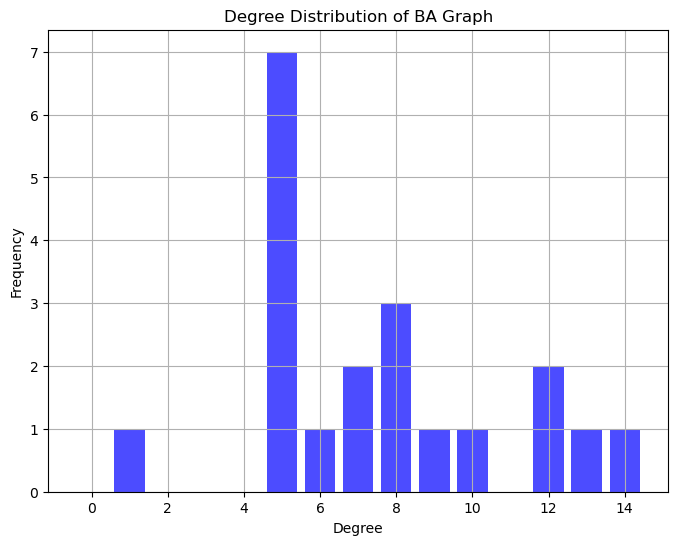

In [26]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

# 生成Watts-Strogatz小世界网络
N = 20
m = 5
G = nx.barabasi_albert_graph(N, m)

# 获取每个节点的度数
degrees = [d for n, d in G.degree()]

# 计算度数的频率
degree_counts = np.bincount(degrees)

# 绘制度分布图
plt.figure(figsize=(8, 6))
plt.bar(range(len(degree_counts)), degree_counts, width=0.8, color='b', alpha=0.7)
plt.xlabel('Degree')
plt.ylabel('Frequency')
plt.title('Degree Distribution of BA Graph')
plt.grid(True)
plt.show()


WS网络的平均度: 8.0
BA网络的平均度: 9.0


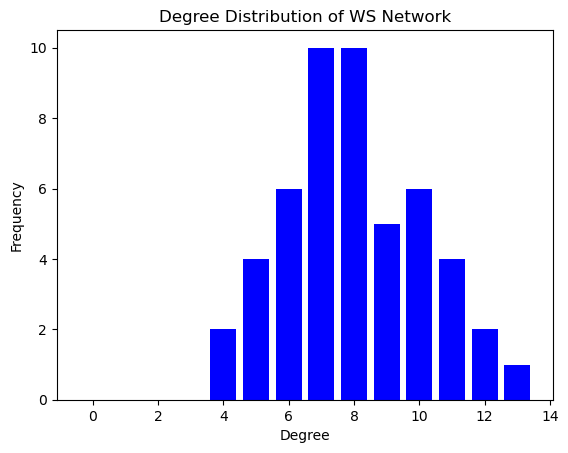

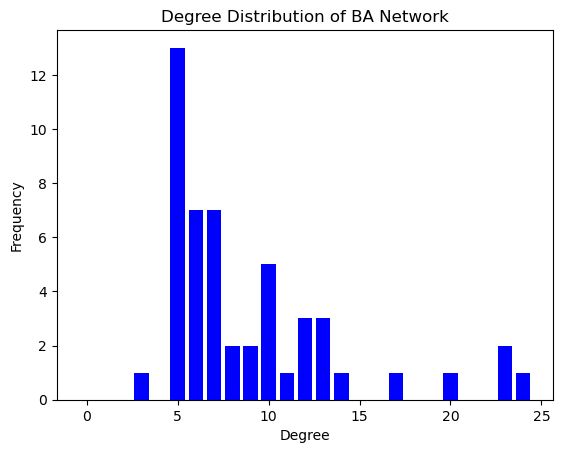

In [3]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

# 设置随机种子以确保结果可复现
np.random.seed(42)

# 节点数量
N = 50

# WS小世界网络参数
k = 8  # 每个节点的初始连接数
p_rewire = 0.8  # 重新连边的概率

# BA无标度网络参数
# m = k // 2  # 每次添加节点的边数（取k的一半）
m = 5

# 生成WS小世界网络
WS_network = nx.watts_strogatz_graph(N, k, p_rewire)

# 生成BA无标度网络
BA_network = nx.barabasi_albert_graph(N, m)

# 计算WS网络的平均度
avg_degree_WS = np.mean([degree for node, degree in WS_network.degree()])

# 计算BA网络的平均度
avg_degree_BA = np.mean([degree for node, degree in BA_network.degree()])

print(f"WS网络的平均度: {avg_degree_WS}")
print(f"BA网络的平均度: {avg_degree_BA}")

# 绘制度分布
def plot_degree_distribution(G, title):
    degree_sequence = sorted([d for n, d in G.degree()], reverse=True)
    degree_count = np.bincount(degree_sequence)
    degrees = np.arange(len(degree_count))

    plt.figure()
    plt.bar(degrees, degree_count, width=0.80, color='b')
    plt.title(title)
    plt.ylabel("Frequency")
    plt.xlabel("Degree")
    plt.show()

# 绘制WS网络的度分布
plot_degree_distribution(WS_network, "Degree Distribution of WS Network")

# 绘制BA网络的度分布
plot_degree_distribution(BA_network, "Degree Distribution of BA Network")
